<a href="https://colab.research.google.com/github/UH-HACKATHON-TEAMN/Hackathon-Town-C/blob/main/ramya.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing & Metrics
from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

# Models
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

# Styling plots
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Load training and testing datasets
train_df = pd.read_csv('dataset_C_training.csv')
test_df = pd.read_csv('dataset_C_testing.csv')

print("Training Set Shape:", train_df.shape)
print("Testing Set Shape:", test_df.shape)

# Display first few rows
display(train_df.head())

# Check data types and target distribution
print("\nTarget Variable Distribution:")
print(train_df['covid_vaccine'].value_counts(normalize=True) * 100)

Training Set Shape: (4756, 31)
Testing Set Shape: (4749, 30)


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1
4,5,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,3,2,2.0,wholesale,0,0



Target Variable Distribution:
covid_vaccine
0    67.325484
1    32.674516
Name: proportion, dtype: float64


In [3]:
# Calculate missing values count and percentage in training data
missing_train = train_df.isnull().sum()
missing_train_pct = (train_df.isnull().sum() / len(train_df)) * 100

missing_df = pd.DataFrame({'Missing Count': missing_train, 'Missing Percentage (%)': missing_train_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0].sort_values(by='Missing Count', ascending=False)

print("Features with Missing Values in Training Set:")
display(missing_df)

Features with Missing Values in Training Set:


,Missing Count,Missing Percentage (%)
employment_sector,2330,48.990749
health_insurance,1908,40.117746
income_poverty,748,15.727502
rent_or_own,329,6.917578
employment_status,238,5.004205
marital_status,231,4.857023
education,228,4.793944
child_under_6_months,135,2.838520
health_worker,132,2.775442
opinion_covid_sick_from_vacc,90,1.892347


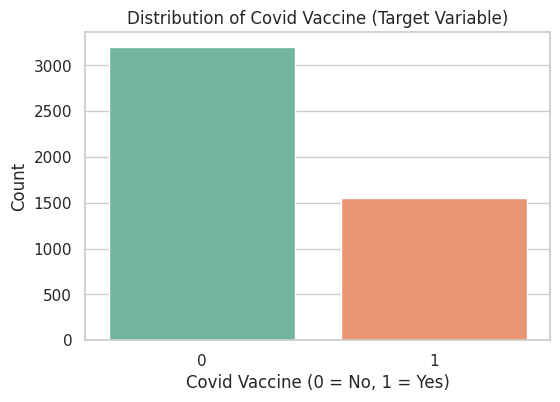

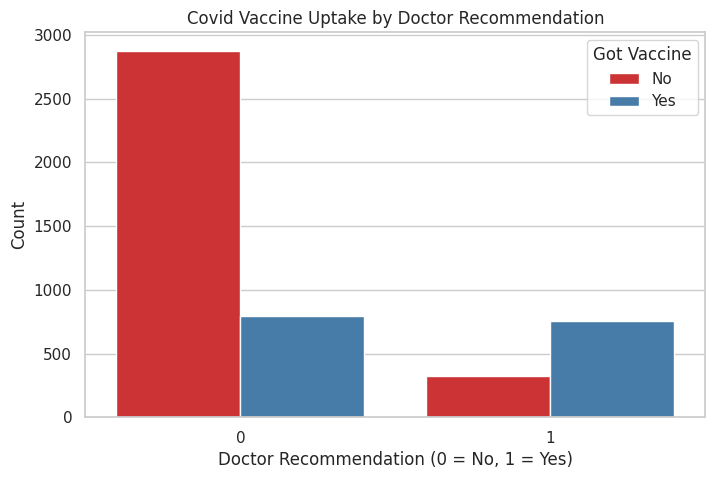

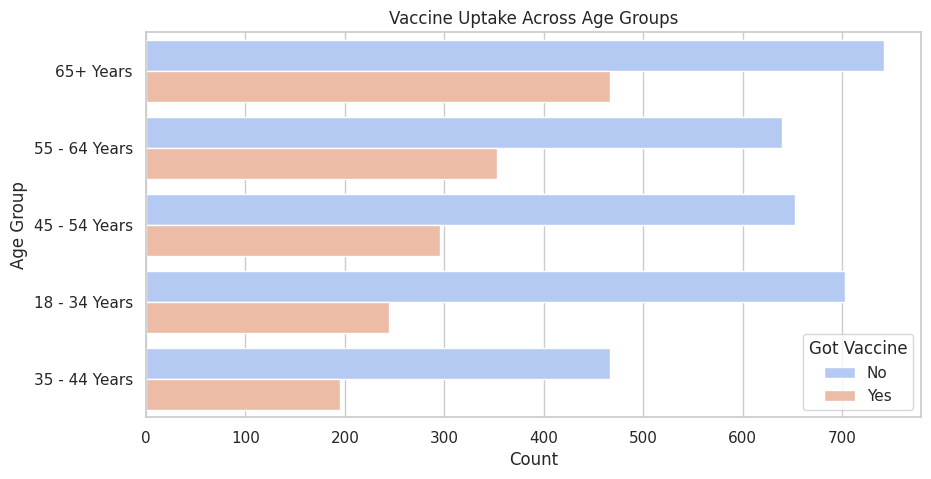

In [4]:
# Plot 1: Target Variable Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x='covid_vaccine', data=train_df, palette='Set2')
plt.title('Distribution of Covid Vaccine (Target Variable)')
plt.xlabel('Covid Vaccine (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.show()

# Plot 2: Doctor Recommendation vs Vaccine Uptake
plt.figure(figsize=(8, 5))
sns.countplot(x='doctor_recc_covid', hue='covid_vaccine', data=train_df, palette='Set1')
plt.title('Covid Vaccine Uptake by Doctor Recommendation')
plt.xlabel('Doctor Recommendation (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.legend(title='Got Vaccine', labels=['No', 'Yes'])
plt.show()

# Plot 3: Age Group vs Vaccine Uptake
plt.figure(figsize=(10, 5))
sns.countplot(y='age_group', hue='covid_vaccine', data=train_df, palette='coolwarm', order=train_df['age_group'].value_counts().index)
plt.title('Vaccine Uptake Across Age Groups')
plt.xlabel('Count')
plt.ylabel('Age Group')
plt.legend(title='Got Vaccine', labels=['No', 'Yes'])
plt.show()

In [5]:
# Separate features and target
X = train_df.drop(columns=['respondent_id', 'covid_vaccine'])
y = train_df['covid_vaccine']

# Identify numerical and categorical columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Numerical Columns ({len(numerical_cols)}):", numerical_cols)
print(f"Categorical Columns ({len(categorical_cols)}):", categorical_cols)

# Create Preprocessing Pipelines for Numerical and Categorical data
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

# Split data into training and validation sets (80% train, 20% val)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

Numerical Columns (19): ['covid_concern', 'covid_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'child_under_6_months', 'health_worker', 'health_insurance', 'household_adults', 'household_children', 'doctor_recc_covid', 'opinion_covid_vacc_effective', 'opinion_covid_risk', 'opinion_covid_sick_from_vacc', 'number_chronic_med_conditions']
Categorical Columns (10): ['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']


In [6]:
def evaluate_model(model, X_v, y_v, model_name="Model"):
    y_pred = model.predict(X_v)
    y_prob = model.predict_proba(X_v)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_v)

    acc = accuracy_score(y_v, y_pred)
    prec = precision_score(y_v, y_pred, zero_division=0)
    rec = recall_score(y_v, y_pred, zero_division=0)
    f1 = f1_score(y_v, y_pred, zero_division=0)
    roc = roc_auc_score(y_v, y_prob)

    print(f"=== {model_name} Performance ===")
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    print(f"ROC-AUC:   {roc:.4f}\n")

    return {'Model': model_name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1': f1, 'ROC-AUC': roc}

results = []

In [7]:
from sklearn.ensemble import RandomForestClassifier

# Define pipeline with preprocessor and Random Forest
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# Hyperparameter grid for Random Forest
rf_param_grid = {
    'classifier__n_estimators': [100, 200, 300],
    'classifier__max_depth': [10, 20, None],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

# Randomized Search for Hyperparameter Tuning
rf_search = RandomizedSearchCV(rf_pipeline, rf_param_grid, n_iter=5, cv=3, scoring='roc_auc', random_state=42, n_jobs=-1)
rf_search.fit(X_train, y_train)

best_rf = rf_search.best_estimator_
print("Best RF Parameters:", rf_search.best_params_)

# Evaluate
results.append(evaluate_model(best_rf, X_val, y_val, "Random Forest"))

Best RF Parameters: {'classifier__n_estimators': 100, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 4, 'classifier__max_depth': 10}
=== Random Forest Performance ===
Accuracy:  0.7889
Precision: 0.7750
Recall:    0.4984
F1-Score:  0.6067
ROC-AUC:   0.8317



In [8]:
# Define pipeline with preprocessor and SVM
svm_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', SVC(probability=True, random_state=42))
])

# Hyperparameter grid for SVM
svm_param_grid = {
    'classifier__C': [0.1, 1, 10],
    'classifier__gamma': ['scale', 'auto', 0.01, 0.1],
    'classifier__kernel': ['linear', 'rbf']
}

# Randomized Search
svm_search = RandomizedSearchCV(svm_pipeline, svm_param_grid, n_iter=4, cv=3, scoring='roc_auc', random_state=42, n_jobs=-1)
svm_search.fit(X_train, y_train)

best_svm = svm_search.best_estimator_
print("Best SVM Parameters:", svm_search.best_params_)

# Evaluate
results.append(evaluate_model(best_svm, X_val, y_val, "Support Vector Machine"))

Best SVM Parameters: {'classifier__kernel': 'linear', 'classifier__gamma': 'scale', 'classifier__C': 10}
=== Support Vector Machine Performance ===
Accuracy:  0.7553
Precision: 0.6726
Recall:    0.4887
F1-Score:  0.5661
ROC-AUC:   0.8186



In [9]:
# Define pipeline with preprocessor and XGBoost
xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(eval_metric='logloss', random_state=42))
])

# Hyperparameter grid for XGBoost
xgb_param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [3, 5, 7],
    'classifier__learning_rate': [0.01, 0.1, 0.2],
    'classifier__subsample': [0.8, 1.0]
}

# Randomized Search
xgb_search = RandomizedSearchCV(xgb_pipeline, xgb_param_grid, n_iter=5, cv=3, scoring='roc_auc', random_state=42, n_jobs=-1)
xgb_search.fit(X_train, y_train)

best_xgb = xgb_search.best_estimator_
print("Best XGBoost Parameters:", xgb_search.best_params_)

# Evaluate
results.append(evaluate_model(best_xgb, X_val, y_val, "XGBoost"))

Best XGBoost Parameters: {'classifier__subsample': 1.0, 'classifier__n_estimators': 100, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.1}
=== XGBoost Performance ===
Accuracy:  0.7952
Precision: 0.7397
Recall:    0.5756
F1-Score:  0.6474
ROC-AUC:   0.8325



In [10]:
# Compile and display model comparison table
results_df = pd.DataFrame(results)
print("=== MODEL COMPARISON TABLE ===")
display(results_df.sort_values(by='ROC-AUC', ascending=False))

# Business Cost Analysis Calculation (as per project brief)
# Costs: Vaccine = $1,500 | Hospitalisation = $41,000
# Assume probability of infection = 100% without vaccine (or reduced if vaccinated)
VACCINE_COST = 1500
HOSP_COST = 41000

def calculate_town_cost(model, X_data, y_true):
    # Predict who wants/takes the vaccine
    preds = model.predict(X_data)

    # Cost calculation logic based on project prompt:
    # 1. Vaccine cost for those who get vaccinated (or compensated if unavailable) -> let's assume predicted 1s get vaccines sent.
    # 2. Hospitalization cost for those who remain unvaccinated (assuming higher hospitalization risk without vaccine).
    # Simple model estimation: Unvaccinated people have higher hospitalisation probability (e.g., 20%), vaccinated have lower (e.g., 2%).
    hosp_prob_unvax = 0.20
    hosp_prob_vax = 0.02

    num_vaccinated = np.sum(preds == 1)
    num_unvaccinated = np.sum(preds == 0)

    total_vaccine_spend = num_vaccinated * VACCINE_COST
    expected_hosp_spend = (num_vaccinated * hosp_prob_vax + num_unvaccinated * hosp_prob_unvax) * HOSP_COST

    total_cost = total_vaccine_spend + expected_hosp_spend
    return total_cost

print("\n=== Business Cost Minimization Analysis ===")
for name, mod in [("Random Forest", best_rf), ("SVM", best_svm), ("XGBoost", best_xgb)]:
    cost = calculate_town_cost(mod, X_val, y_val)
    print(f"{name} - Estimated Total Town Cost: ${cost:,.2f}")

=== MODEL COMPARISON TABLE ===


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
2,XGBoost,0.795168,0.739669,0.575563,0.647378,0.832456
0,Random Forest,0.788866,0.775000,0.498392,0.606654,0.831659
1,Support Vector Machine,0.755252,0.672566,0.488746,0.566108,0.818641



=== Business Cost Minimization Analysis ===
Random Forest - Estimated Total Town Cost: $6,630,400.00
SVM - Estimated Total Town Cost: $6,477,520.00
XGBoost - Estimated Total Town Cost: $6,383,440.00


In [11]:
# Assuming 'best_xgb' (or whichever model performed best on your validation set) is your final model
# Replace 'best_xgb' with 'best_rf' or 'best_svm' if another model scored higher.

final_model = best_xgb  # Change to best_rf or best_svm if needed

# Drop respondent_id from test set for prediction
X_test = test_df.drop(columns=['respondent_id'])

# Predict binary labels (0 or 1) and probabilities
test_predictions = final_model.predict(X_test)
test_probabilities = final_model.predict_proba(X_test)[:, 1]

# Create submission DataFrame
submission_df = pd.DataFrame({
    'respondent_id': test_df['respondent_id'],
    'covid_vaccine_prediction': test_predictions,
    'covid_vaccine_probability': test_probabilities
})

# Save to CSV
submission_filename = 'dataset_C_predictions_submission.csv'
submission_df.to_csv(submission_filename, index=False)

print(f"=== Submission File Generated Successfully: '{submission_filename}' ===")
display(submission_df.head(10))

# Check distribution of predictions
print("\nPredicted Class Distribution on Test Set:")
print(submission_df['covid_vaccine_prediction'].value_counts(normalize=True) * 100)

=== Submission File Generated Successfully: 'dataset_C_predictions_submission.csv' ===


,respondent_id,covid_vaccine_prediction,covid_vaccine_probability
0,4757,0,0.175065
1,4758,0,0.169076
2,4759,0,0.163968
3,4760,0,0.326936
4,4761,0,0.055871
5,4762,1,0.618663
6,4763,0,0.455114
7,4764,1,0.853173
8,4765,1,0.851532
9,4766,0,0.308348



Predicted Class Distribution on Test Set:
covid_vaccine_prediction
0    73.510213
1    26.489787
Name: proportion, dtype: float64
